<a href="https://colab.research.google.com/github/ThePretelR/cassava-disease-model-comparison/blob/main/notebooks/01_exploracion_datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys
import tensorflow as tf
import tensorflow_datasets as tfds

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPU disponibles:", gpus)

if gpus:
    print("GPU detectada correctamente")
else:
    print("No se detectó GPU")


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU detectada correctamente


In [3]:
%pip install importlib_resources

In [4]:

import importlib_resources

print("Biblioteca importlib_resources instalada correctamente")


Biblioteca importlib_resources instalada correctamente


In [5]:

import tensorflow_datasets as tfds
import tensorflow as tf

# Nombre y versión del dataset
DATASET_NAME = "cassava"
DATASET_VERSION = "0.1.0"

# Descargar y cargar las particiones oficiales
(ds_train, ds_val, ds_test), ds_info = tfds.load(
    f"{DATASET_NAME}:{DATASET_VERSION}",
    split=["train", "validation", "test"],
    as_supervised=True,
    with_info=True,
    shuffle_files=False
)

print("Dataset cargado correctamente")
print("Nombre:", ds_info.name)
print("Versión:", ds_info.version)

print("\nCantidad de imágenes:")
print("Entrenamiento:", ds_info.splits["train"].num_examples)
print("Validación:", ds_info.splits["validation"].num_examples)
print("Prueba:", ds_info.splits["test"].num_examples)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.JL1TTV_0.1.0/cassava-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.JL1TTV_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.JL1TTV_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.
Dataset cargado correctamente
Nombre: cassava
Versión: 0.1.0

Cantidad de imágenes:
Entrenamiento: 5656
Validación: 1889
Prueba: 1885


In [6]:
## 2. Exploracion de las Clases

# Obtener los nombres de las clases
class_names = ds_info.features["label"].names

print("Número de clases:", len(class_names))
print("\nClases encontradas:")

for i, nombre in enumerate(class_names):
    print(f"{i}: {nombre}")

Número de clases: 5

Clases encontradas:
0: cbb
1: cbsd
2: cgm
3: cmd
4: healthy


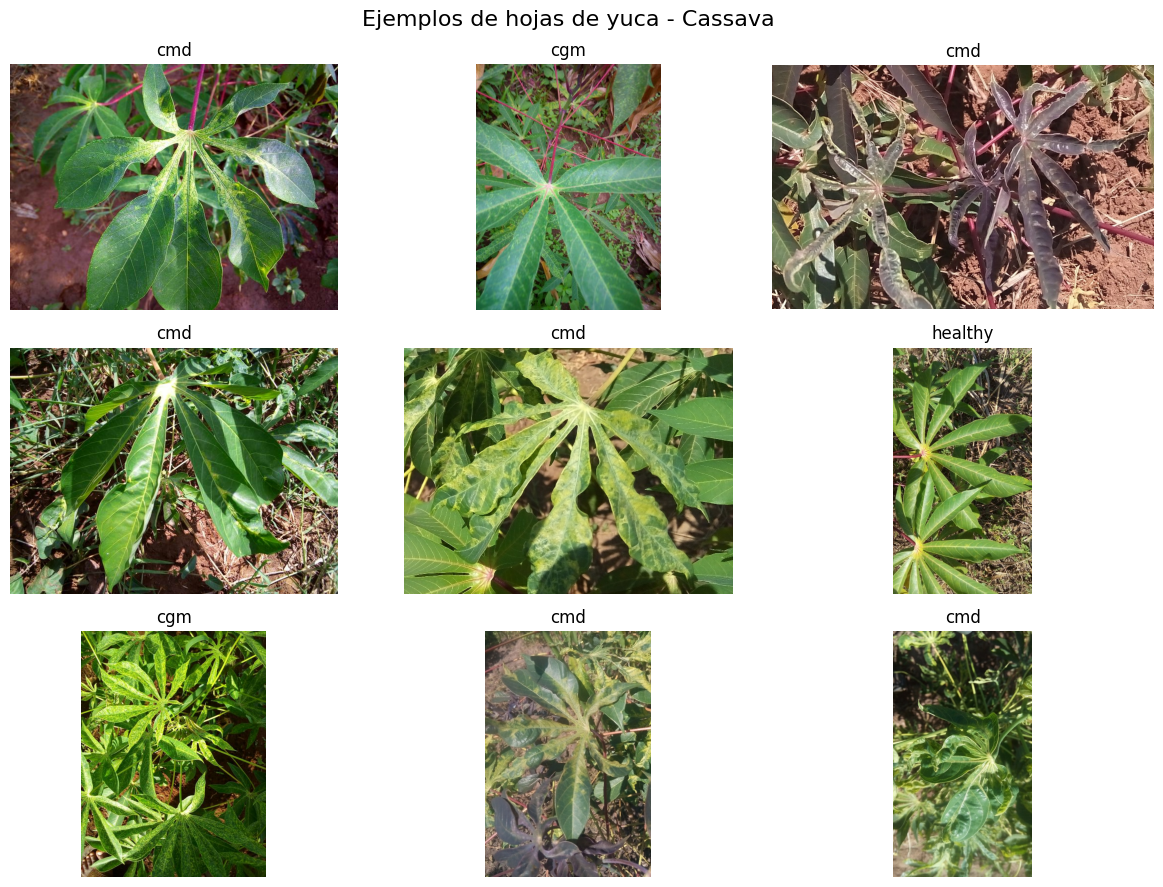

In [7]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 9))

# Mostrar las primeras 9 imágenes de entrenamiento
for i, (imagen, etiqueta) in enumerate(ds_train.take(9)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(imagen.numpy())
    plt.title(class_names[int(etiqueta.numpy())])
    plt.axis("off")

plt.suptitle("Ejemplos de hojas de yuca - Cassava", fontsize=16)
plt.tight_layout()
plt.show()

Distribución de clases en entrenamiento:

cbb: 466 imágenes (8.24%)
cbsd: 1443 imágenes (25.51%)
cgm: 773 imágenes (13.67%)
cmd: 2658 imágenes (46.99%)
healthy: 316 imágenes (5.59%)


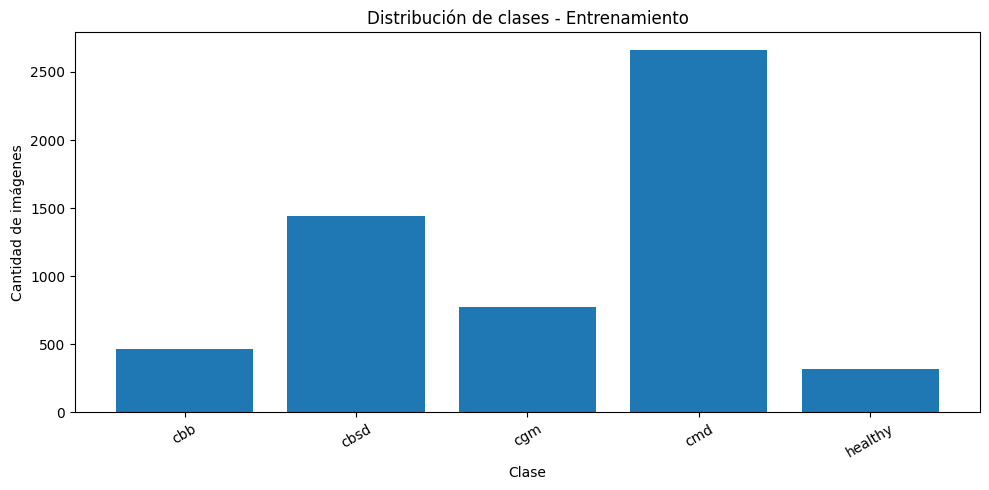

In [8]:

import numpy as np
import matplotlib.pyplot as plt

# Contar las etiquetas del conjunto de entrenamiento
conteos = np.zeros(len(class_names), dtype=int)

for imagen, etiqueta in ds_train:
    conteos[int(etiqueta.numpy())] += 1

# Mostrar resultados
print("Distribución de clases en entrenamiento:\n")

for nombre, cantidad in zip(class_names, conteos):
    porcentaje = cantidad / sum(conteos) * 100
    print(f"{nombre}: {cantidad} imágenes ({porcentaje:.2f}%)")

# Crear gráfica
plt.figure(figsize=(10, 5))
plt.bar(class_names, conteos)

plt.title("Distribución de clases - Entrenamiento")
plt.xlabel("Clase")
plt.ylabel("Cantidad de imágenes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()